# Figure 3 — Nested-CV comparison on healthy vs BRCA+CRC (Cristiano cohort)

- (a) mean ROC over the 10 outer test folds: data-driven model, ATAC, RNA and ichorCNA;
- (b) share of samples called cancer at the 95%-specificity threshold of each outer training fold, for
  healthy donors, all cancers and by ichorCNA tumor fraction (pooled counts, Clopper-Pearson intervals);
- (c) paired per-sample posterior differences relative to the data-driven model, by class (Healthy,
  stage I–IV), one-sided Wilcoxon signed-rank tests, Holm-adjusted.

Source data in `data/<cohort>/` (default `data/no_deep/`): `fig3_predictions.csv` (out-of-fold scores,
fold, label, train-derived 95%-specificity threshold, stage; `n_rows_in_source` = row multiplicity in the
ichorCNA table), `fig3_config.csv`, `fig3_model_selection.csv`, written by `export/export_fig3.py`;
`fig3b_calls.csv` (from `figS_strata.ipynb`); `stats_method_comparisons.csv` (from
`export/export_method_comparisons.py`). Run top to bottom from `src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch: "no_deep" (default) = without the 30 deep-sequenced healthy controls, "all" = full cohort.
# Set FIG_COHORT in the environment. Files a variant has not exported fall back to data/ with a notice.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.metrics import roc_curve, auc

APPROACH_COLORS = {
    "RNA": "#CA3542",        # crimson
    "ATAC": "#ECB22E",       # gold/amber
    "Data-driven": "#0173B2",  # deep blue
    "ichorCNA": "#6A3D9A",   # purple
}
METHOD_LABELS = {"data_driven": "Data-driven", "atac": "ATAC", "rna": "RNA", "ichorcna": "ichorCNA"}
STAGES = ["I", "II", "III", "IV"]

# Manuscript-figure style (src/figures/_figstyle.py); applied only while Figure 3 is drawn
import _figstyle as fs
FIG_NAME = {"data_driven": "Data-driven", "atac": "ATAC-seq", "rna": "RNA-seq", "ichorcna": "ichorCNA"}

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
pred = pd.read_csv(data_path("fig3_predictions.csv"))
config = pd.read_csv(data_path("fig3_config.csv"))
display(config)

task = pred[pred["method"] == "data_driven"]
print(f"task samples: {task['sample_id'].nunique()} "
      f"({(task['y_true'] == 0).sum()} healthy, {(task['y_true'] == 1).sum()} cancer), "
      f"folds: {task['fold'].nunique()}")
ichor_all = pred[pred["method"] == "ichorcna"]
print(f"ichorCNA rows: {len(ichor_all)} samples "
      f"({int(ichor_all['fold'].notna().sum())} inside the task folds)")

,method,feature,classifier,weighting_function,top_genes,source_dir,selection_mean_auc,note
0,data_driven,griffin_diff,Support Vector Machine,fold_change,10000.0,nested_cv_results_cris/nested_full_brca_crc_ne...,0.965717,fully nested: config chosen per fold; modal sh...
1,rna,rcov,XGBoost,NaN,NaN,nested_cv_results_cris/brca_crc_rna_rev_nodeep,0.665533,fully nested: classifier chosen per fold on in...
2,atac,ulz_atac_tfbs_features,Logistic Regression,NaN,NaN,nested_cv_results_cris/brca_crc_atac_rev_nodeep,0.890579,fully nested: classifier chosen per fold on in...
3,ichorcna,ichorcna_tf,NaN,NaN,NaN,accessory_files/cris_stage_vaf_coverage_ichor_...,NaN,NaN


task samples: 244 (164 healthy, 80 cancer), folds: 10
ichorCNA rows: 367 samples (244 inside the task folds)


## Helpers

ichorCNA: per outer fold, the 95%-specificity threshold is derived from all samples not in that fold's
test set (the whole ichorCNA table, other cancer types included); `n_rows_in_source` repeats rows that
are duplicated in that table.

In [3]:
def expand(df):
    """Repeat rows by their multiplicity in the original ichorCNA table."""
    return df.loc[df.index.repeat(df["n_rows_in_source"])]


def fold_rocs(df):
    """Per-fold ROC curves and AUCs from out-of-fold scores."""
    out = []
    for _, g in df.groupby("fold"):
        g = expand(g).dropna(subset=["score"])
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        out.append((fpr, tpr, auc(fpr, tpr)))
    return out


def ichor_fold_threshold(fold):
    """95%-specificity threshold from the ichorCNA 'training' split of a fold."""
    train = ichor_all[(ichor_all["fold"] != fold) | ichor_all["fold"].isna()]
    train = expand(train).dropna(subset=["score"])
    fpr_tr, tpr_tr, thr_tr = roc_curve(train["y_true"], train["score"])
    idx = np.where(1 - fpr_tr >= 0.95)[0]
    return thr_tr[idx[-1]]


def binary_metrics(y, y_hat):
    tn = int(np.sum((y == 0) & (y_hat == 0)))
    fp = int(np.sum((y == 0) & (y_hat == 1)))
    fn = int(np.sum((y == 1) & (y_hat == 0)))
    tp = int(np.sum((y == 1) & (y_hat == 1)))
    m = {
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "specificity": tn / (tn + fp) if tn + fp else 0.0,
    }
    # Precision/F1 are undefined when a fold makes no positive predictions
    # (TP+FP == 0); those folds are skipped for precision/F1 only.
    if tp + fp:
        m["precision"] = tp / (tp + fp)
        m["f1-score"] = 2 * m["precision"] * m["recall"] / (m["precision"] + m["recall"]) \
            if (m["precision"] + m["recall"]) else 0.0
    return m


def collect_fold_metrics(method):
    """Per-fold metrics at the fold's 95%-specificity threshold."""
    df = pred[pred["method"] == method]
    folds = sorted(df["fold"].dropna().unique())
    per_fold = []
    for f in folds:
        g = expand(df[df["fold"] == f]).dropna(subset=["score"])
        thr = ichor_fold_threshold(f) if method == "ichorcna" else g["threshold_95spec"].iloc[0]
        per_fold.append(binary_metrics(g["y_true"].to_numpy(), (g["score"] >= thr).to_numpy().astype(int)))
    keys = ["precision", "recall", "f1-score", "accuracy", "specificity"]
    return {k: [m[k] for m in per_fold if k in m] for k in keys}

## Panel a — mean ROC over the outer folds

In [4]:
def panel_a(ax):
    base_fpr = np.linspace(0, 1, 101)
    for method in ["data_driven", "atac", "rna", "ichorcna"]:
        name = FIG_NAME[method]
        color = fs.METHOD[name]
        df = pred[(pred["method"] == method) & pred["fold"].notna()]
        tprs, aucs = [], []
        for fpr, tpr, a in fold_rocs(df):
            tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
            aucs.append(a)
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0, 1
        std_tpr = np.std(tprs, axis=0)
        ax.plot(base_fpr, mean_tpr, color=color, zorder=3,
                label=f"{name}  {np.mean(aucs):.3f} \u00b1 {np.std(aucs):.3f}")
        ax.fill_between(base_fpr, np.maximum(mean_tpr - std_tpr, 0),
                        np.minimum(mean_tpr + std_tpr, 1), color=color, alpha=0.13, linewidth=0)
    ax.plot([0, 1], [0, 1], color=fs.CHANCE, linestyle=":", linewidth=0.8)
    ax.axvline(x=0.05, color=fs.NEUTRAL, linestyle=(0, (3, 2)), linewidth=0.7, zorder=1,
               label="95% specificity")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    # no frame line; a white fill keeps the chance diagonal and the bands from running through the text
    leg = ax.legend(loc="lower right", title="AUROC (mean \u00b1 SD)", alignment="left",
                    handlelength=1.0, handletextpad=0.5, borderaxespad=0.1,
                    frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
    leg.set_zorder(5)

## Panel b — calls at the 95%-specificity operating point

`panel_b_calls` draws the figure panel; `panel_b` (fold-mean metrics with error bars) is not used in the
assembled figure.

In [5]:
def panel_b(ax, approach_metrics, error_type="sem"):
    metric_names = ["Precision", "Sensitivity\n(recall)", "F1-score", "Accuracy", "Specificity"]
    metric_keys = ["precision", "recall", "f1-score", "accuracy", "specificity"]
    x = np.arange(len(metric_names))
    width = 0.2
    order = ["data_driven", "atac", "rna", "ichorcna"]
    for idx, method in enumerate(order):
        label = FIG_NAME[method]
        m = approach_metrics[method]
        means = [np.mean(m[k]) if m[k] else 0 for k in metric_keys]
        if error_type == "sem":
            errs = [np.std(m[k], ddof=1) / np.sqrt(len(m[k])) if len(m[k]) > 1 else 0
                    for k in metric_keys]
        else:
            errs = [np.std(m[k]) if m[k] else 0 for k in metric_keys]
        yerr_lo = [min(e, mu) for mu, e in zip(means, errs)]
        yerr_hi = [min(e, 1.0 - mu) for mu, e in zip(means, errs)]
        offset = (idx - (len(order) - 1) / 2) * width
        ax.bar(x + offset, means, width * 0.92, yerr=[yerr_lo, yerr_hi], label=label,
               color=fs.METHOD[label], capsize=1.2, zorder=2,
               error_kw={"elinewidth": 0.6, "capthick": 0.6, "ecolor": fs.NEUTRAL})
        # value labels: vertical, just above the error bar, so neighbouring bars never collide
        for i, v in enumerate(means):
            ax.text(i + offset, v + yerr_hi[i] + 0.015, f"{v:.2f}", ha="center", va="bottom",
                    rotation=90, fontsize=fs.VALUE)
    ax.set_ylabel("Score")
    ax.set_xticks(x)
    ax.set_xticklabels(metric_names)
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_ylim(0, 1.17)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    fs.value_grid(ax)


def panel_b_calls(ax, task="brca_crc"):
    """b: share of samples called cancer at the 95%-specificity threshold of each outer fold's training samples,
    per method, for the healthy donors, all cancers and the cancers by ichorCNA tumor fraction; pooled counts with
    exact (Clopper-Pearson) 95% intervals. Source: data/no_deep/fig3b_calls.csv (figS_strata.ipynb, the same calls
    as the pan-cancer panel of the strata figure)."""
    tab = pd.read_csv(data_path("fig3b_calls.csv"))
    tab = tab[tab["task"] == task]
    groups = ["Healthy", "All cancers", "TF < 0.01", "0.01 <= TF < 0.03", "TF >= 0.03"]
    tick = {"Healthy": "Healthy", "All cancers": "All", "TF < 0.01": "< 0.01", "0.01 <= TF < 0.03": "0.01–0.03",
            "TF >= 0.03": "≥ 0.03"}
    order = ["data_driven", "atac", "rna", "ichorcna"]
    assert set(tab["group"]) == set(groups) and set(tab["method"]) == set(order)
    offs = np.linspace(-0.3, 0.3, len(order))
    for mi, m in enumerate(order):
        label = FIG_NAME[m]
        for i, g in enumerate(groups):
            r = tab[(tab["group"] == g) & (tab["method"] == m)].iloc[0]
            k, n, v = int(r["called"]), int(r["n"]), r["share"]
            ax.errorbar(i + offs[mi], v, yerr=[[v - r["lo"]], [r["hi"] - v]], fmt="o", ms=3, color=fs.METHOD[label],
                        mec="white", mew=0.4, elinewidth=0.9, capsize=0, label=label if i == 0 else None, zorder=3,
                        clip_on=False)
            ax.text(i + offs[mi], r["hi"] + 0.02, f"{k}/{n}", ha="center", va="bottom", fontsize=fs.VALUE,
                    color="#333333", rotation=90)
    for x in (0.5, 1.5):
        ax.vlines(x, -0.03, 1.28, color=fs.CHANCE, ls=":", lw=0.6)
    ax.axhline(0.05, color=fs.CHANCE, ls="--", lw=0.6)     # 5% = the false-positive share the threshold aims at
    n_of = tab.drop_duplicates("group").set_index("group")["n"]
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"{tick[g]}\nn = {int(n_of[g])}" for g in groups])
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(groups) - 0.5)
    ax.set_xlabel("ichorCNA tumor fraction", x=3.5 / 5)      # under the three tumor-fraction groups
    ax.set_ylim(-0.03, 1.55)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylabel("Share called cancer")
    fs.value_grid(ax)
    ax.legend(loc="upper left", ncol=2, handletextpad=0.1, columnspacing=1.0, borderaxespad=0.1, labelspacing=0.3)
    c = tab.set_index(["group", "method"])
    assert (c.loc[("All cancers", "data_driven"), "called"], c.loc[("Healthy", "data_driven"), "called"]) == (65, 8)


## Panel c — paired posterior differences by class

Per sample: data-driven posterior minus baseline posterior (ichorCNA: tumor fraction as score). One-sided
Wilcoxon signed-rank tests: stages H1 data-driven > baseline, Healthy H1 data-driven < baseline. Stars =
Holm-adjusted p over the 15 tests (five groups × three baselines); the table lists raw and adjusted p.

In [6]:
def _sig_marker(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def holm(pvals):
    """Holm step-down adjusted p-values (valid under arbitrary dependence)."""
    p = np.asarray(pvals, dtype=float)
    order = p.argsort()
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


def panel_c(ax, rng_seed=0):
    in_task = pred[pred["fold"].notna()]
    prob = {}   # method -> {sample_id: score}
    for method in METHOD_LABELS:
        g = in_task[in_task["method"] == method].dropna(subset=["score"])
        prob[method] = g.drop_duplicates("sample_id").set_index("sample_id")["score"].to_dict()

    sample_info = in_task[in_task["method"] == "data_driven"] \
        .drop_duplicates("sample_id").set_index("sample_id")[["y_true", "stage"]]

    def ids_for(cat):
        if cat == "Healthy":
            return set(sample_info[sample_info["y_true"] == 0].index)
        return set(sample_info[(sample_info["y_true"] == 1) & (sample_info["stage"] == cat)].index)

    comparisons = ["ATAC", "RNA", "ichorCNA"]
    comp_methods = {"ATAC": "atac", "RNA": "rna", "ichorCNA": "ichorcna"}
    comp_colors = [fs.METHOD[FIG_NAME[comp_methods[c]]] for c in comparisons]
    categories = ["Healthy"] + STAGES

    diff_records, test_results = [], {}
    for cat in categories:
        cat_ids = ids_for(cat)
        alternative = "less" if cat == "Healthy" else "greater"
        for comp in comparisons:
            comp_prob = prob[comp_methods[comp]]
            common = [s for s in cat_ids if s in prob["data_driven"] and s in comp_prob]
            diffs = np.array([prob["data_driven"][s] - comp_prob[s] for s in common])
            for s, d in zip(common, diffs):
                diff_records.append({"Category": cat, "Comparison": f"vs {comp}", "Difference": d})
            if len(diffs) >= 5 and not np.all(diffs == 0):
                _, p_dir = stats.wilcoxon(diffs, alternative=alternative)
            else:
                p_dir = np.nan
            test_results[(cat, comp)] = {"n": len(diffs), "median": np.median(diffs),
                                         "p_directional": p_dir, "alternative": alternative}
    diff_df = pd.DataFrame(diff_records)

    # Holm over every test of the panel (5 groups x 3 baselines); a second column
    # adjusts per baseline over the five groups, for comparison only
    keys = [k for k, r in test_results.items() if not np.isnan(r["p_directional"])]
    for k, p_adj in zip(keys, holm([test_results[k]["p_directional"] for k in keys])):
        test_results[k]["p_holm"] = p_adj
    for comp in comparisons:
        sub = [k for k in keys if k[1] == comp]
        for k, p_adj in zip(sub, holm([test_results[k]["p_directional"] for k in sub])):
            test_results[k]["p_holm_per_baseline"] = p_adj

    rng = np.random.default_rng(rng_seed)  # jitter only; fixed for reproducible layout
    from matplotlib.colors import to_rgba
    n_comps = len(comparisons)
    box_width = 0.24
    cat_positions = np.arange(len(categories))
    offsets = np.linspace(-box_width * (n_comps - 1) / 2, box_width * (n_comps - 1) / 2, n_comps)

    for c_idx, comp in enumerate(comparisons):
        positions = cat_positions + offsets[c_idx]
        box_data = [diff_df[(diff_df["Category"] == cat) & (diff_df["Comparison"] == f"vs {comp}")]
                    ["Difference"].values for cat in categories]
        bp = ax.boxplot(box_data, positions=positions, widths=box_width * 0.85,
                        patch_artist=True, showfliers=False,
                        medianprops=dict(color="black", linewidth=0.8),
                        boxprops=dict(linewidth=0.5, edgecolor=fs.NEUTRAL),
                        whiskerprops=dict(linewidth=0.5, color=fs.NEUTRAL),
                        capprops=dict(linewidth=0.5, color=fs.NEUTRAL))
        for patch in bp["boxes"]:
            patch.set_facecolor(to_rgba(comp_colors[c_idx], 0.4))
        jitter = box_width * 0.28
        for s_idx, vals in enumerate(box_data):
            if len(vals):
                x_jit = positions[s_idx] + rng.uniform(-jitter, jitter, len(vals))
                ax.scatter(x_jit, vals, s=2.5, color=comp_colors[c_idx], alpha=0.75,
                           edgecolors="none", zorder=3)

    ax.axhline(y=0, color=fs.CHANCE, linestyle=":", linewidth=0.8, zorder=1)
    # significance marks: one row per baseline, rows a full text height apart (no overlaps)
    bracket_y_base, bracket_step = 1.06, 0.15
    for s_idx, cat in enumerate(categories):
        for c_idx, comp in enumerate(comparisons):
            if np.isnan(test_results[(cat, comp)]["p_directional"]):
                continue
            p_d = test_results[(cat, comp)]["p_holm"]
            sig = _sig_marker(p_d)
            ax.text(cat_positions[s_idx] + offsets[c_idx], bracket_y_base + c_idx * bracket_step,
                    sig, ha="center", va="bottom", fontsize=fs.VALUE,
                    fontweight="bold" if sig != "ns" else "normal",
                    color=comp_colors[c_idx], alpha=1.0 if sig != "ns" else 0.7)

    ax.set_xticks(cat_positions)
    ax.set_xticklabels(["Healthy"] + STAGES)
    ax.set_xlabel("Cancer stage")
    ax.xaxis.set_label_coords(0.6, -0.075)   # centred under the four stages
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel("Posterior difference\n(data-driven \u2212 baseline)")
    ax.set_xlim(-0.5, len(categories) - 0.5)
    ax.set_ylim([-1.32, bracket_y_base + n_comps * bracket_step + 0.02])
    ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    fs.value_grid(ax)
    ax.vlines(0.5, -1.05, ax.get_ylim()[1], color=fs.CHANCE, linestyle=":", linewidth=0.6)  # stops above the legend strip
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], marker="s", color="w", markerfacecolor=to_rgba(comp_colors[i], 0.6),
                      markersize=5, label=FIG_NAME[comp_methods[comp]], markeredgecolor="none")
               for i, comp in enumerate(comparisons)]
    # one legend row in a strip below the data (y < -1), so it covers no point
    ax.legend(handles=handles, loc="lower center", ncol=n_comps, handlelength=0.7, handletextpad=0.3,
              columnspacing=0.7, borderaxespad=0.1)
    return test_results

## Assemble Figure 3

saved output\no_deep\fig3.png/.pdf at 178 x 70 mm


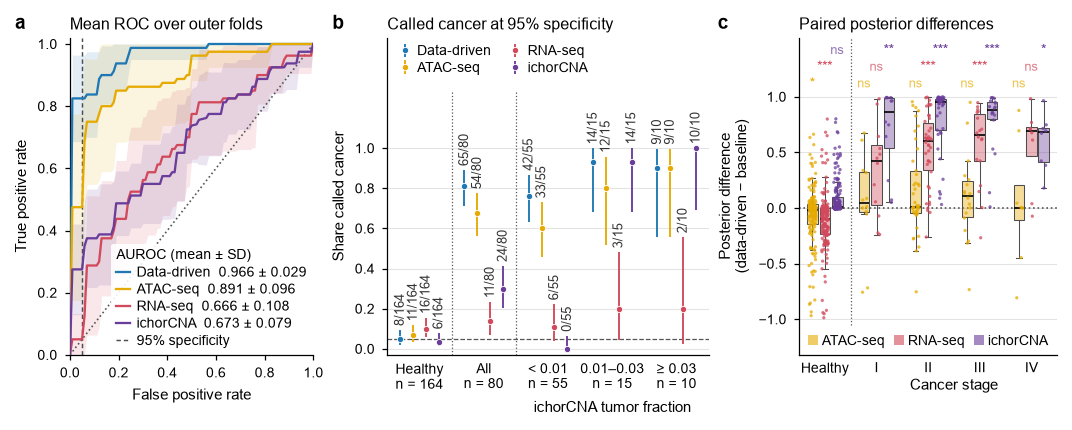

,group,baseline,n,median difference,alternative,p,"p (Holm, all 15)","p (Holm, per baseline)",sig
0,Healthy,ATAC,164,-0.0187,less,0.001246,0.01121,0.006229,*
1,Healthy,RNA,164,-0.09954,less,3.651e-12,5.112e-11,1.826e-11,***
2,Healthy,ichorCNA,164,0.01212,less,1,1,1,ns
3,I,ATAC,12,0.04253,greater,0.2593,0.6914,0.4609,ns
4,I,RNA,12,0.4245,greater,0.01343,0.08203,0.02344,ns
5,I,ichorCNA,12,0.8669,greater,0.0002441,0.002441,0.0007324,**
6,II,ATAC,42,0.01347,greater,0.02598,0.1299,0.1039,ns
7,II,RNA,42,0.6019,greater,4.707e-11,6.119e-10,1.883e-10,***
8,II,ichorCNA,42,0.9572,greater,2.274e-13,3.411e-12,1.137e-12,***
9,III,ATAC,18,0.109,greater,0.1419,0.5675,0.4256,ns


In [7]:
approach_metrics = {m: collect_fold_metrics(m) for m in METHOD_LABELS}

with plt.rc_context():          # the shared main-figure style, for this figure only
    fs.apply()
    fig, (ax_a, ax_b, ax_c) = plt.subplots(
        1, 3, figsize=fs.size(height=2.75), layout="constrained",
        gridspec_kw={"width_ratios": [1.0, 1.32, 1.06]})
    panel_a(ax_a)
    panel_b_calls(ax_b)   # pooled counts with exact intervals
    test_results = panel_c(ax_c)
    fs.panel(ax_a, "a", "Mean ROC over outer folds")
    fs.panel(ax_b, "b", "Called cancer at 95% specificity")
    fs.panel(ax_c, "c", "Paired posterior differences")
    fs.save(fig, out_path("fig3"))
    plt.show()

panel_c_tests = pd.DataFrame([
    {"group": cat, "baseline": comp, "n": r["n"], "median difference": r["median"],
     "alternative": r["alternative"], "p": r["p_directional"],
     "p (Holm, all 15)": r.get("p_holm", np.nan),
     "p (Holm, per baseline)": r.get("p_holm_per_baseline", np.nan),
     "sig": _sig_marker(r["p_holm"]) if "p_holm" in r else ""}
    for (cat, comp), r in test_results.items()])
panel_c_tests.to_csv(out_path("fig3c_tests.csv"), index=False, lineterminator="\n")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(panel_c_tests)

## What the figure's uncertainty graphics mean

- Panel a: per-fold ROC curves interpolated onto 101 FPR points; line = mean TPR over the 10 outer folds,
  band = ±1 SD of the fold TPRs (fold-to-fold variability, not a confidence interval).
- Panel b: pooled share called cancer with exact (Clopper-Pearson) 95% intervals.
- Panel c: one jittered dot per sample; box = IQR, line = median, whiskers 1.5×IQR.

## DeLong tests between ROC curves

Pairwise DeLong tests (fast DeLong, Sun & Xu 2014) on the pooled out-of-fold scores of the 274 samples
scored by all four methods. The pooled scores of the 10 fold models are treated as one scoring function
(fold dependence ignored). Holm over the three comparisons against the data-driven model (primary
family); Holm over all 6 pairs is also reported.

In [8]:
import itertools


def _midrank(x):
    """Midranks (ties averaged), 1-based — Sun & Xu (2014) fast DeLong."""
    J = np.argsort(x); Z = x[J]; N = len(x)
    T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(N); out[J] = T
    return out


def delong_cov(y, score_mat):
    """AUCs and DeLong covariance matrix for k correlated ROC curves evaluated
    on the SAME samples. y: (n,) in {0,1}; score_mat: (k, n)."""
    order = np.argsort(-y)              # positives first
    y_s = y[order]; score_mat = score_mat[:, order]
    m = int(y_s.sum()); n_neg = len(y_s) - m
    pos, neg = score_mat[:, :m], score_mat[:, m:]
    tx = np.array([_midrank(p) for p in pos])
    ty = np.array([_midrank(q) for q in neg])
    tz = np.array([_midrank(np.concatenate([p, q])) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(axis=1) / (m * n_neg) - (m + 1.0) / (2.0 * n_neg)
    v01 = (tz[:, :m] - tx) / n_neg
    v10 = 1.0 - (tz[:, m:] - ty) / m
    return aucs, np.cov(v01) / m + np.cov(v10) / n_neg


def delong_test(y, s1, s2):
    """Two-sided DeLong test for a difference between two correlated AUCs."""
    aucs, S = delong_cov(y, np.vstack([s1, s2]))
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return aucs, z, 2 * stats.norm.sf(abs(z))


# Paired pooled-OOF scores: the 274 task samples scored by all four methods.
_in_task = pred[pred["fold"].notna()].drop_duplicates(["method", "sample_id"])
_wide = _in_task.pivot_table(index="sample_id", columns="method", values="score")
_y_ser = _in_task[_in_task["method"] == "data_driven"].set_index("sample_id")["y_true"]
_wide = _wide.loc[_y_ser.index].dropna()
_y = _y_ser.loc[_wide.index].to_numpy()
assert len(_wide) == task["sample_id"].nunique(), \
    "DeLong table does not cover the full task cohort"

_methods = ["data_driven", "atac", "rna", "ichorcna"]
_aucs, _ = delong_cov(_y, _wide[_methods].to_numpy().T)
print(f"pooled OOF AUCs on {len(_wide)} paired samples (+{_y.sum()}/-{(_y == 0).sum()}):")
for m_, a_ in zip(_methods, _aucs):
    print(f"  {METHOD_LABELS[m_]:<12} {a_:.4f}")

delong_rows = []
for a_, b_ in itertools.combinations(_methods, 2):
    (auc1, auc2), z, p = delong_test(_y, _wide[a_].to_numpy(), _wide[b_].to_numpy())
    delong_rows.append({"method A": METHOD_LABELS[a_], "method B": METHOD_LABELS[b_],
                        "AUC A": auc1, "AUC B": auc2, "ΔAUC": auc1 - auc2,
                        "z": z, "p (two-sided)": p})
delong_df = pd.DataFrame(delong_rows)

# Primary family: the three pre-specified comparisons against the data-driven
# model (the manuscript's claims). Holm over 3; the full 6-pair family is also
# adjusted for completeness (baseline-vs-baseline pairs are descriptive).
primary_mask = delong_df["method A"] == "Data-driven"
delong_df["p (Holm, all 6)"] = holm(delong_df["p (two-sided)"])
delong_df.loc[primary_mask, "p (Holm, primary 3)"] = \
    holm(delong_df.loc[primary_mask, "p (two-sided)"])
delong_df["sig"] = delong_df["p (Holm, primary 3)"] \
    .fillna(delong_df["p (Holm, all 6)"]).map(_sig_marker)
display(delong_df.round({"AUC A": 4, "AUC B": 4, "ΔAUC": 4, "z": 2}))

pooled OOF AUCs on 244 paired samples (+80/-164):
  Data-driven  0.9598
  ATAC         0.8925
  RNA          0.6132
  ichorCNA     0.6721


,method A,method B,AUC A,AUC B,ΔAUC,z,p (two-sided),"p (Holm, all 6)","p (Holm, primary 3)",sig
0,Data-driven,ATAC,0.9598,0.8925,0.0674,2.83,4.644948e-03,9.289897e-03,4.644948e-03,**
1,Data-driven,RNA,0.9598,0.6132,0.3466,8.79,1.547145e-18,9.282867e-18,4.641434e-18,***
2,Data-driven,ichorCNA,0.9598,0.6721,0.2877,7.30,2.922067e-13,1.461034e-12,5.844135e-13,***
3,ATAC,RNA,0.8925,0.6132,0.2793,6.97,3.242232e-12,1.296893e-11,NaN,***
4,ATAC,ichorCNA,0.8925,0.6721,0.2204,5.27,1.387312e-07,4.161936e-07,NaN,***
5,RNA,ichorCNA,0.6132,0.6721,-0.0589,-1.19,2.356344e-01,2.356344e-01,NaN,ns


## Comparison that accounts for the overlapping training sets (both tasks)

Corrected resampled $t$-test (Nadeau and Bengio 2003) on the ten paired fold AUROCs (variance
$(1/k + n_{test}/n_{train})\,s^2$), with DeLong and participant-bootstrap intervals (2,000 resamples),
Holm over the three baselines per task; from `export/export_method_comparisons.py`
(`stats_method_comparisons.csv`). The cell checks that its BRCA/CRC DeLong values equal the table above.

In [9]:
cmp = pd.read_csv(data_path("stats_method_comparisons.csv"))
# the exporter's DeLong values for BRCA/CRC must be this notebook's own
_mine = delong_df[delong_df["method A"] == "Data-driven"].set_index("method B")
for _, r in cmp[cmp["task"] == "BRCA/CRC vs healthy"].iterrows():
    m = _mine.loc[r["baseline"]]
    assert abs(m["ΔAUC"] - r["delong_diff"]) < 1e-9, r["baseline"]
    assert abs(m["p (Holm, primary 3)"] - r["delong_p_holm"]) < 1e-9, r["baseline"]
print("exporter DeLong values = this notebook's (BRCA/CRC, 3 baselines)\n")
for _, r in cmp[cmp["corrected_t_p"].notna()].iterrows():
    print(f"{r['task']:<22} vs {r['baseline']:<8} fold means {r['fold_mean_dd']:.3f} vs {r['fold_mean_base']:.3f}, "
          f"higher in {int(r['folds_dd_higher'])}/10 folds | corrected t: {r['fold_diff_mean']:+.3f} "
          f"({r['corrected_t_ci_lo']:+.3f} to {r['corrected_t_ci_hi']:+.3f}), Holm p = {r['corrected_t_p_holm']:.2g} | "
          f"DeLong: {r['delong_diff']:+.3f} ({r['delong_ci_lo']:+.3f} to {r['delong_ci_hi']:+.3f}), Holm p = {r['delong_p_holm']:.2g}")
for _, r in cmp[cmp["corrected_t_p"].isna()].iterrows():
    print(f"{r['task']} vs {r['baseline']}: {r['pooled_auc_dd']:.3f} ({r['pooled_auc_dd_lo']:.3f}-{r['pooled_auc_dd_hi']:.3f}) vs "
          f"{r['pooled_auc_base']:.3f} ({r['pooled_auc_base_lo']:.3f}-{r['pooled_auc_base_hi']:.3f}); DeLong {r['delong_diff']:+.3f} "
          f"({r['delong_ci_lo']:+.3f} to {r['delong_ci_hi']:+.3f}), Holm p = {r['delong_p_holm']:.2g}")


exporter DeLong values = this notebook's (BRCA/CRC, 3 baselines)

BRCA/CRC vs healthy    vs ATAC     fold means 0.966 vs 0.891, higher in 9/10 folds | corrected t: +0.075 (-0.038 to +0.188), Holm p = 0.17 | DeLong: +0.067 (+0.021 to +0.114), Holm p = 0.0046
BRCA/CRC vs healthy    vs RNA      fold means 0.966 vs 0.666, higher in 10/10 folds | corrected t: +0.300 (+0.190 to +0.410), Holm p = 0.00033 | DeLong: +0.347 (+0.269 to +0.424), Holm p = 4.6e-18
BRCA/CRC vs healthy    vs ichorCNA fold means 0.966 vs 0.673, higher in 10/10 folds | corrected t: +0.292 (+0.192 to +0.393), Holm p = 0.0003 | DeLong: +0.288 (+0.210 to +0.365), Holm p = 5.8e-13
Pan-cancer vs healthy  vs ATAC     fold means 0.969 vs 0.897, higher in 9/10 folds | corrected t: +0.073 (+0.010 to +0.135), Holm p = 0.028 | DeLong: +0.083 (+0.049 to +0.118), Holm p = 2.1e-06
Pan-cancer vs healthy  vs RNA      fold means 0.969 vs 0.676, higher in 10/10 folds | corrected t: +0.293 (+0.217 to +0.370), Holm p = 3.6e-05 | DeLong: +0

## Summary values

In [10]:
ref = {
    "data_driven": (0.951, 0.039), "atac": (0.913, 0.064),
    "rna": (0.680, 0.118), "ichorcna": (0.600, 0.086),
}
print("mean AUC over folds (computed vs manuscript Fig 3a legend):")
for method in ref:
    aucs = [a for _, _, a in fold_rocs(pred[(pred["method"] == method) & pred["fold"].notna()])]
    print(f"  {METHOD_LABELS[method]:<12} {np.mean(aucs):.3f} ± {np.std(aucs):.3f}   "
          f"(manuscript: {ref[method][0]:.3f} ± {ref[method][1]:.3f})")

print("\nData-driven metrics at 95% specificity (manuscript Fig 3b: "
      "0.87 / 0.79 / 0.82 / 0.90 / 0.95):")
m = approach_metrics["data_driven"]
print("  " + " / ".join(f"{np.mean(m[k]):.2f}" for k in
                        ["precision", "recall", "f1-score", "accuracy", "specificity"]))

print("\nPanel c directional Wilcoxon p-values (stars: Holm-adjusted over the 15 tests):")
for (cat, comp), r in test_results.items():
    print(f"  {cat:<8} vs {comp:<9} n={r['n']:>3}  median diff={r['median']:+.3f}  "
          f"p={r['p_directional']:.2e}  Holm p={r['p_holm']:.2e} ({_sig_marker(r['p_holm'])})")

mean AUC over folds (computed vs manuscript Fig 3a legend):
  Data-driven  0.966 ± 0.029   (manuscript: 0.951 ± 0.039)
  ATAC         0.891 ± 0.096   (manuscript: 0.913 ± 0.064)
  RNA          0.666 ± 0.108   (manuscript: 0.680 ± 0.118)
  ichorCNA     0.673 ± 0.079   (manuscript: 0.600 ± 0.086)

Data-driven metrics at 95% specificity (manuscript Fig 3b: 0.87 / 0.79 / 0.82 / 0.90 / 0.95):
  0.90 / 0.81 / 0.84 / 0.91 / 0.95

Panel c directional Wilcoxon p-values (stars: Holm-adjusted over the 15 tests):
  Healthy  vs ATAC      n=164  median diff=-0.019  p=1.25e-03  Holm p=1.12e-02 (*)
  Healthy  vs RNA       n=164  median diff=-0.100  p=3.65e-12  Holm p=5.11e-11 (***)
  Healthy  vs ichorCNA  n=164  median diff=+0.012  p=1.00e+00  Holm p=1.00e+00 (ns)
  I        vs ATAC      n= 12  median diff=+0.043  p=2.59e-01  Holm p=6.91e-01 (ns)
  I        vs RNA       n= 12  median diff=+0.425  p=1.34e-02  Holm p=8.20e-02 (ns)
  I        vs ichorCNA  n= 12  median diff=+0.867  p=2.44e-04  Holm p=2.4

# QC — under-the-hood diagnostics

Verification only, on the exported data plus `data/fig3_model_selection.csv` and
`accessory_files/cris_manifest.csv`:

1. Cohort audit: every task sample has manifest role `model` (no excluded, panel-of-normals or replicate
   samples); flags stage values that would drop samples from panel c.
2. Fold integrity: each sample once per method, identical outer partition across arms, class composition per fold.
3. Model selection: RNA locked to `rcov`, ATAC to the Ulz TFBS matrix; the data-driven winner per fold is
   the inner-score argmax.
4. AUC conventions: per-fold AUCs, pooled OOF vs mean of folds.
5. Operating point: train-derived thresholds and achieved test specificity per fold (should scatter around 0.95).
6. Score distributions by class and the worst healthy false positives.

In [11]:
# --- QC 1: cohort audit against the manifest ---------------------------------
from pathlib import Path

task_ids = set(task["sample_id"])
manifest_path = Path("../../accessory_files/cris_manifest.csv")
if manifest_path.exists():
    man = pd.read_csv(manifest_path).set_index("ID")
    in_task = man.loc[man.index.intersection(task_ids)]

    print("manifest role x disease of the 274 task samples:")
    display(in_task.groupby(["role", "disease"]).size().unstack(fill_value=0))

    bad_roles = in_task[in_task["role"].isin(["excluded", "panel_of_normals"])]
    assert bad_roles.empty, \
        f"excluded/panel_of_normals samples inside the task cohort: {list(bad_roles.index)}"

    # No sample may be in the task together with its second-run replicate,
    # and no flagged replicate may be in the task at all.
    reps = man[man["replicate_of"].notna()]
    rep_in_task = [rid for rid in reps.index if rid in task_ids]
    assert not rep_in_task, f"second-run replicates inside the task cohort: {rep_in_task}"

    missing = task_ids - set(man.index)
    assert not missing, f"task samples absent from the manifest: {sorted(missing)[:5]}"
    print(f"\nOK — all {len(task_ids)} task samples carry role 'model'; no excluded / "
          "panel-of-normals / replicate contamination.")
else:
    print("manifest not found relative to src/figures/ — cohort audit skipped")

# Stage annotation hygiene: whitespace or unexpected values silently drop
# samples from panel c's stage groups (it matches stage == 'I' etc. exactly).
cancer_stages = task.loc[task["y_true"] == 1, "stage"]
odd = cancer_stages.dropna()[~cancer_stages.dropna().isin(STAGES)]
if len(odd):
    print(f"\n⚠️  {len(odd)} cancer sample(s) with a stage value outside {STAGES}: "
          f"{odd.unique().tolist()} — these are EXCLUDED from panel c's stage groups. "
          "Fix in the export (e.g. .str.strip()) if unintended.")
n_nostage = int(cancer_stages.isna().sum())
if n_nostage:
    print(f"⚠️  {n_nostage} cancer sample(s) without stage annotation (excluded from panel c).")

manifest role x disease of the 274 task samples:


disease,Breast cancer,Colorectal cancer,Healthy
role,,,
model,54,26,164



OK — all 244 task samples carry role 'model'; no excluded / panel-of-normals / replicate contamination.


OK — identical 10-fold partition across data_driven / rna / atac; each sample scored exactly once (true out-of-fold).


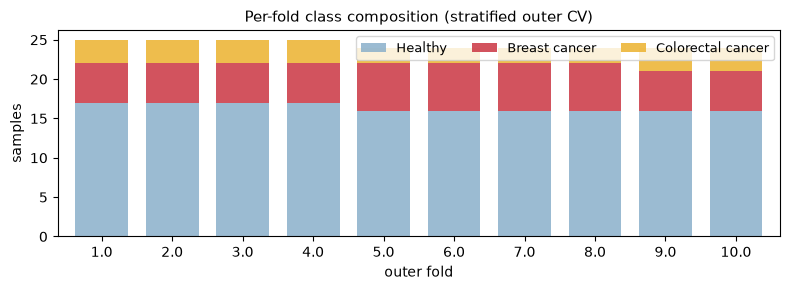

fold,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
disease,,,,,,,,,,
Healthy,17,17,17,17,16,16,16,16,16,16
Breast cancer,5,5,5,5,6,6,6,6,5,5
Colorectal cancer,3,3,3,3,2,2,2,2,3,3


In [12]:
# --- QC 2: outer-fold integrity and composition ------------------------------
ml_methods = ["data_driven", "rna", "atac"]

parts = {}
for m in ml_methods:
    g = pred[(pred["method"] == m) & pred["fold"].notna()]
    assert g["sample_id"].is_unique, f"{m}: sample appears in more than one fold"
    assert set(g["sample_id"]) == task_ids, f"{m}: cohort differs from data_driven"
    parts[m] = g.groupby("fold")["sample_id"].apply(frozenset).to_dict()
assert parts["data_driven"] == parts["rna"] == parts["atac"], \
    "outer-fold partitions differ between arms"
print("OK — identical 10-fold partition across data_driven / rna / atac; "
      "each sample scored exactly once (true out-of-fold).")

comp = task.groupby(["fold", "disease"]).size().unstack(fill_value=0)[
    ["Healthy", "Breast cancer", "Colorectal cancer"]]
fig, ax = plt.subplots(figsize=(8, 3))
comp.plot(kind="bar", stacked=True, ax=ax, width=0.75,
          color=["#8AAFCA", "#CA3542", "#ECB22E"], alpha=0.85)
ax.set_xlabel("outer fold"); ax.set_ylabel("samples")
ax.set_title("Per-fold class composition (stratified outer CV)", fontsize=11)
ax.legend(fontsize=9, ncol=3); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
display(comp.T)

OK — RNA locked to rcov, ATAC locked to ulz_atac_tfbs_features (candidates and config).

data_driven — configuration chosen PER FOLD on inner scores only:


,feature,selection_type,top_genes,classifier,inner_cv_auc,test_auc
fold,,,,,,
1,griffin_diff,fold_change,10000,Support Vector Machine,0.971939,0.911765
2,griffin_diff,p_value,10000,Support Vector Machine,0.973639,0.963235
3,griffin_diff,fold_change,10000,Support Vector Machine,0.961451,0.985294
4,griffin_diff,fold_change,10000,Support Vector Machine,0.968254,1.000000
5,griffin_diff,mean_diff,15000,Support Vector Machine,0.973549,0.921875
6,griffin_diff,mean_diff,15000,Support Vector Machine,0.967681,1.000000
7,griffin_diff,fold_change,10000,Support Vector Machine,0.956485,0.968750
8,griffin_diff,fold_change,10000,Support Vector Machine,0.960176,0.984375
9,griffin_diff,fold_change,10000,Support Vector Machine,0.958605,0.945312


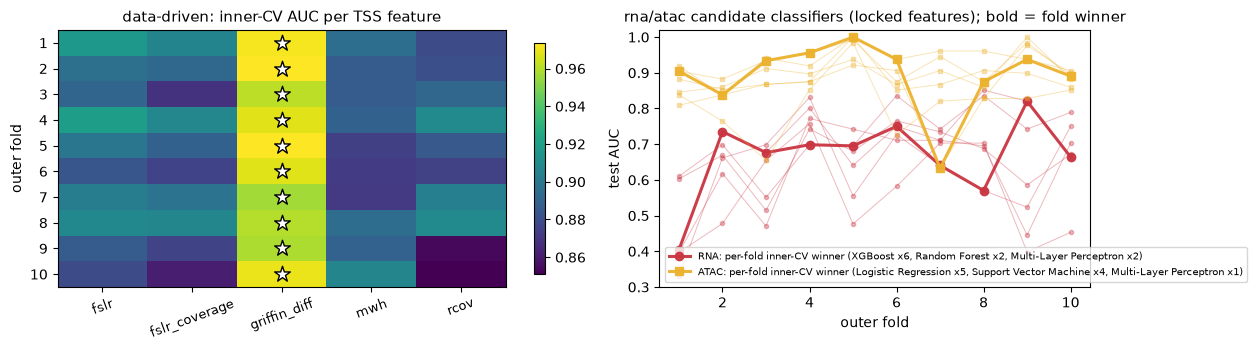

OK — every data_driven fold winner is the argmax of its inner-score landscape (feature selection is nested, not post-hoc).


In [13]:
# --- QC 3: model-selection audit ----------------------------------------------
# data/fig3_model_selection.csv (written by export_fig3.py) holds the per-fold
# selection trail: the data_driven winner + its inner-score landscape over all
# five TSS features, and every candidate classifier for rna/atac on their
# LOCKED feature.
sel_path = Path(data_path("fig3_model_selection.csv"))
if not sel_path.exists():
    print("data/fig3_model_selection.csv not found — rerun export_fig3.py")
else:
    sel = pd.read_csv(sel_path)

    # Feature locks: RNA may only ever be rcov, ATAC only the Ulz TFBS matrix.
    assert set(sel.loc[sel["method"] == "rna", "feature"]) == {"rcov"}
    assert set(sel.loc[sel["method"] == "atac", "feature"]) == {"ulz_atac_tfbs_features"}
    assert config.set_index("method").loc["rna", "feature"] == "rcov"
    assert config.set_index("method").loc["atac", "feature"] == "ulz_atac_tfbs_features"
    print("OK — RNA locked to rcov, ATAC locked to ulz_atac_tfbs_features "
          "(candidates and config).")

    dd = sel[sel["method"] == "data_driven"]
    dd_win = dd[dd["chosen"]].set_index("fold")
    print("\ndata_driven — configuration chosen PER FOLD on inner scores only:")
    display(dd_win[["feature", "selection_type", "top_genes", "classifier",
                    "inner_cv_auc", "test_auc"]])

    # Inner-score landscape: was the winning feature actually the inner argmax?
    land = dd.pivot_table(index="fold", columns="feature", values="inner_cv_auc")
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
    im = axes[0].imshow(land.values, aspect="auto", cmap="viridis")
    axes[0].set_xticks(range(len(land.columns)), land.columns, rotation=20, fontsize=9)
    axes[0].set_yticks(range(len(land.index)), land.index)
    axes[0].set_ylabel("outer fold")
    axes[0].set_title("data-driven: inner-CV AUC per TSS feature", fontsize=11)
    for i, f in enumerate(land.index):
        j = list(land.columns).index(dd_win.loc[f, "feature"])
        axes[0].scatter(j, i, marker="*", s=140, c="white", edgecolors="black", zorder=3)
        assert land.loc[f].idxmax() == dd_win.loc[f, "feature"], \
            f"fold {f}: winner is not the inner-score argmax!"
    fig.colorbar(im, ax=axes[0], shrink=0.9)

    # rna/atac: candidate classifiers on the locked feature, outer test AUC per
    # fold; the chosen classifier is drawn bold.
    ax = axes[1]
    for method, marker in [("rna", "o"), ("atac", "s")]:
        cand = sel[sel["method"] == method]
        color = APPROACH_COLORS[METHOD_LABELS[method]]
        for clf, g in cand.groupby("classifier"):
            g = g.sort_values("fold")
            ax.plot(g["fold"], g["test_auc"], marker=marker, markersize=3, linewidth=0.7,
                    alpha=0.35, color=color)
        win = cand[cand["chosen"]].sort_values("fold")
        # fully nested: the classifier chosen PER FOLD on inner-CV scores (bold)
        assert win["fold"].is_unique and len(win) == 10, f"{method}: expected one winner per fold"
        assert all(win.set_index("fold").loc[f, "inner_cv_auc"] >= cand[cand["fold"] == f]["inner_cv_auc"].max() - 1e-12
                   for f in win["fold"]), f"{method}: a fold winner is not the inner-score argmax"
        ax.plot(win["fold"], win["test_auc"], marker=marker, markersize=6, linewidth=2.2,
                alpha=0.95, color=color,
                label=f"{METHOD_LABELS[method]}: per-fold inner-CV winner "
                      f"({', '.join(f'{c} x{n}' for c, n in win['classifier'].value_counts().items())})")
    ax.set_xlabel("outer fold"); ax.set_ylabel("test AUC"); ax.set_ylim(0.3, 1.02)
    ax.set_title("rna/atac candidate classifiers (locked features); bold = fold winner", fontsize=11)
    ax.legend(fontsize=7.5, loc="lower left")
    plt.tight_layout(); plt.show()
    print("OK — every data_driven fold winner is the argmax of its inner-score "
          "landscape (feature selection is nested, not post-hoc).")

    n_inner = int(sel[sel["method"].isin(["rna", "atac"])]["inner_cv_auc"].notna().sum())
    if n_inner == 0:
        print("NOTE: rna/atac inner_cv_auc still empty — classifier choice is by mean "
              "outer AUC until slurm/nested_classifier_selection.sh has run and the "
              "export is rerun.")

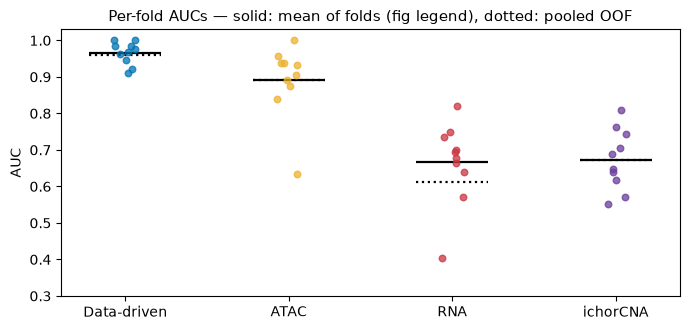

,mean of fold AUCs,sd,pooled OOF AUC,min fold,max fold
method,,,,,
Data-driven,0.9657,0.0291,0.9598,0.9118,1.0000
ATAC,0.8906,0.0960,0.8925,0.6328,1.0000
RNA,0.6655,0.1077,0.6132,0.4044,0.8203
ichorCNA,0.6733,0.0791,0.6721,0.5515,0.8088


The manuscript quotes the mean-of-folds convention; pooled OOF is the more
stable estimate with ~27-sample test folds — the gap between the two columns
is fold-size noise, not a discrepancy.


In [14]:
# --- QC 4: per-fold AUCs and the two reporting conventions --------------------
fig, ax = plt.subplots(figsize=(7, 3.4))
rows = []
rng = np.random.default_rng(0)
for i, method in enumerate(["data_driven", "atac", "rna", "ichorcna"]):
    name = METHOD_LABELS[method]
    df = pred[(pred["method"] == method) & pred["fold"].notna()]
    fold_aucs = [a for _, _, a in fold_rocs(df)]
    g = expand(df).dropna(subset=["score"])
    fpr_p, tpr_p, _ = roc_curve(g["y_true"], g["score"])
    pooled = auc(fpr_p, tpr_p)
    ax.scatter(np.full(len(fold_aucs), i) + rng.uniform(-0.07, 0.07, len(fold_aucs)),
               fold_aucs, s=22, alpha=0.75, color=APPROACH_COLORS[name], zorder=3)
    ax.hlines(np.mean(fold_aucs), i - 0.22, i + 0.22, color="black", linewidth=1.6)
    ax.hlines(pooled, i - 0.22, i + 0.22, color="black", linewidth=1.6, linestyle=":")
    rows.append({"method": name, "mean of fold AUCs": np.mean(fold_aucs),
                 "sd": np.std(fold_aucs), "pooled OOF AUC": pooled,
                 "min fold": np.min(fold_aucs), "max fold": np.max(fold_aucs)})
ax.set_xticks(range(4), [METHOD_LABELS[m] for m in ["data_driven", "atac", "rna", "ichorcna"]])
ax.set_ylabel("AUC"); ax.set_ylim(0.3, 1.03)
ax.set_title("Per-fold AUCs — solid: mean of folds (fig legend), dotted: pooled OOF",
             fontsize=10.5)
plt.tight_layout(); plt.show()
qc_auc = pd.DataFrame(rows).set_index("method").round(4)
display(qc_auc)
print("The manuscript quotes the mean-of-folds convention; pooled OOF is the more\n"
      "stable estimate with ~27-sample test folds — the gap between the two columns\n"
      "is fold-size noise, not a discrepancy.")

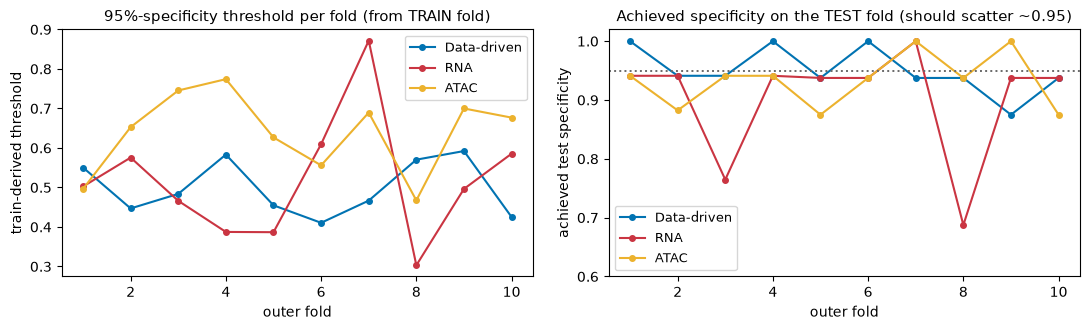

Data-driven  achieved specificity: mean 0.951, range [0.875, 1.000], 4 distinct values across 10 folds
RNA          achieved specificity: mean 0.903, range [0.688, 1.000], 5 distinct values across 10 folds
ATAC         achieved specificity: mean 0.933, range [0.875, 1.000], 5 distinct values across 10 folds


In [15]:
# --- QC 5: operating-point sanity --------------------------------------------
# Thresholds come from the training fold, so the achieved test specificity
# should scatter around 0.95 rather than sit at one value in every fold.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

for method in ml_methods:
    name = METHOD_LABELS[method]
    df = pred[(pred["method"] == method) & pred["fold"].notna()]
    thr = df.groupby("fold")["threshold_95spec"].first()
    assert df.groupby("fold")["threshold_95spec"].nunique().eq(1).all(), \
        f"{method}: threshold varies within a fold"
    assert np.isfinite(thr).all(), f"{method}: non-finite 95%-spec threshold " \
        "(resubstitution-degenerate scores — see derive_operating_point_thresholds)"
    axes[0].plot(thr.index, thr.values, marker="o", markersize=4,
                 color=APPROACH_COLORS[name], label=name)

    specs = collect_fold_metrics(method)["specificity"]
    axes[1].plot(sorted(thr.index), specs, marker="o", markersize=4,
                 color=APPROACH_COLORS[name], label=name)
    if len(set(np.round(specs, 6))) == 1:
        print(f"⚠️  {name}: achieved test specificity is IDENTICAL in all folds "
              f"({specs[0]:.4f}) — the old test-fold-threshold leakage fingerprint. "
              "Check that the run postdates the threshold fix.")

axes[0].set_xlabel("outer fold"); axes[0].set_ylabel("train-derived threshold")
axes[0].set_title("95%-specificity threshold per fold (from TRAIN fold)", fontsize=10.5)
axes[0].legend(fontsize=9)
axes[1].axhline(0.95, color="dimgray", linestyle=":", linewidth=1.4)
axes[1].set_xlabel("outer fold"); axes[1].set_ylabel("achieved test specificity")
axes[1].set_ylim(0.6, 1.02)
axes[1].set_title("Achieved specificity on the TEST fold (should scatter ~0.95)",
                  fontsize=10.5)
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

for method in ml_methods:
    specs = collect_fold_metrics(method)["specificity"]
    print(f"{METHOD_LABELS[method]:<12} achieved specificity: "
          f"mean {np.mean(specs):.3f}, range [{np.min(specs):.3f}, {np.max(specs):.3f}], "
          f"{len(set(np.round(specs, 6)))} distinct values across {len(specs)} folds")

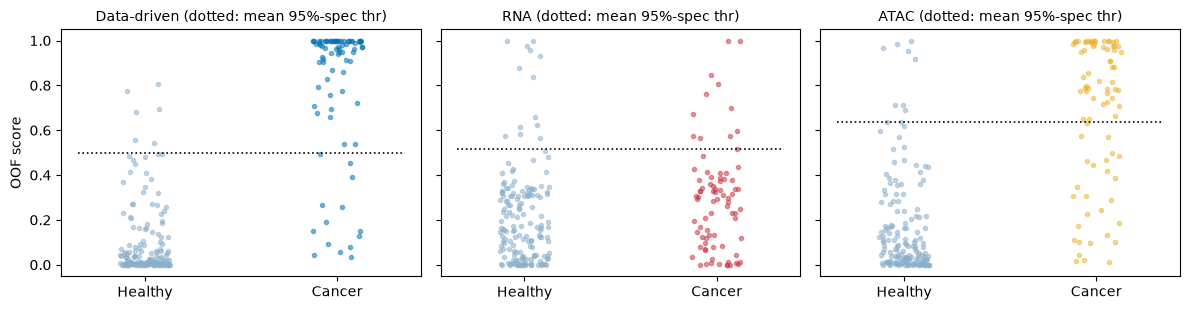

Top healthy samples by data-driven score (potential false positives):


,data_driven,atac,rna,ichorcna,disease
sample_id,,,,,
EE88008,0.804,0.170,0.004,0.002,Healthy
EE88021,0.775,0.112,0.250,0.005,Healthy
EE87994,0.694,0.124,0.044,0.009,Healthy
EE88149,0.681,0.279,0.000,0.004,Healthy
EE88153,0.556,0.333,0.973,0.007,Healthy
EE88144,0.545,0.148,0.079,0.007,Healthy
EE88129,0.494,0.013,0.351,0.005,Healthy
EE88150,0.492,0.045,0.001,0.006,Healthy


OK — all top healthy FPs are ordinary role='model' samples (no replicate/PON stragglers).


In [16]:
# --- QC 6: score distributions and worst healthy false positives -------------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
rng = np.random.default_rng(1)
for ax, method in zip(axes, ml_methods):
    name = METHOD_LABELS[method]
    df = pred[(pred["method"] == method) & pred["fold"].notna()]
    for x0, (label, sub) in enumerate([("Healthy", df[df["y_true"] == 0]),
                                       ("Cancer", df[df["y_true"] == 1])]):
        ax.scatter(np.full(len(sub), x0) + rng.uniform(-0.13, 0.13, len(sub)),
                   sub["score"], s=9, alpha=0.5,
                   color="#8AAFCA" if label == "Healthy" else APPROACH_COLORS[name])
    thr = df.groupby("fold")["threshold_95spec"].first()
    ax.hlines(thr.mean(), -0.35, 1.35, color="black", linestyle=":", linewidth=1.2)
    ax.set_xticks([0, 1], ["Healthy", "Cancer"])
    ax.set_title(f"{name} (dotted: mean 95%-spec thr)", fontsize=10)
axes[0].set_ylabel("OOF score")
plt.tight_layout(); plt.show()

# Worst healthy false positives of the data-driven model, with the other arms'
# scores; all must be ordinary role='model' samples.
wide = (pred[pred["fold"].notna()]
        .pivot_table(index="sample_id", columns="method", values="score")
        .join(task.set_index("sample_id")[["y_true", "disease"]]))
top_fp = wide[wide["y_true"] == 0].nlargest(8, "data_driven")
print("Top healthy samples by data-driven score (potential false positives):")
display(top_fp[["data_driven", "atac", "rna", "ichorcna", "disease"]].round(3))
if manifest_path.exists():
    fp_roles = man.loc[man.index.intersection(top_fp.index), ["role", "exclusion_reason"]]
    assert (fp_roles["role"] == "model").all(), \
        f"non-model samples among top FPs: {fp_roles[fp_roles['role'] != 'model']}"
    print("OK — all top healthy FPs are ordinary role='model' samples "
          "(no replicate/PON stragglers).")